# Mobile-Former on CheXpert (multi-label chest X-ray)

Mobile-Former (Chen et al., CVPR 2022) trained **from scratch** on the same CheXpert-derived dataset used in `Multiscale_MobileFormer_Chexpert.ipynb`.

**How the dataset is used in the reference notebook (and here):**
- Task is **multi-label**, not multi-class: each image gets **3 independent binary labels** (Cardiomegaly, Edema, Pneumothorax). Label = 1 only if the CSV value is exactly `1.0` (uncertain `-1` and missing values become 0).
- Output layer: 3 logits with **sigmoid + `BCEWithLogitsLoss`**, threshold 0.5. Metrics are one binary report / confusion matrix / ROC per label.
- Data: `metadata.csv` with a `new_path` column and one 0/1 column per label, images loaded as RGB 224x224, ImageNet normalisation.
- The reference does one random 80/20 split (`random_state=42`). Here the data is a **stratified subset** split 80/10/10 into train/val/test, so you can report test curves too (the splits therefore differ from the reference's).

Outputs: train/val/test loss, accuracy, macro F1 / precision / recall / AUC curves; per-label confusion matrices, classification reports and ROC curves; parameter and FLOP counts.

**Native resolution:** `IMG_SIZE = None` keeps the images at the size they are stored in (no resizing), as agreed for CheXpert. Set `IMG_SIZE = 224` for a square resize.

In [4]:
!pip install -q seaborn scikit-learn pandas tqdm

## 1. Config

**Subset mode:** this notebook draws a **stratified subset (half of the full dataset by default)** (keeps the label mix of the full data), decodes and resizes it to 224x224 **once** (the first run takes a while, roughly several minutes to a few tens of minutes depending on the CPU), caches it as `.npz` files for re-runs (~2.5 GB for 50k images), and then trains straight from RAM with no dataloader workers. That removes JPEG decoding and worker processes, which are the usual cause of 3-hour epochs and worker crashes.

In [5]:
import os, time, math, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

# ---------------- paths (same as the reference notebook) ----------------
DATA_DIR = "/kaggle/input/datasets/shiv28/chest-xray-4class-100k"       # folder containing metadata.csv and the images
LABELS   = ["Cardiomegaly", "Edema", "Pneumothorax"]    # 3 independent binary labels
NUM_CLASSES = len(LABELS)

# ---------------- subset size (before the 80/10/10 split) ----------------
SUBSET_FRACTION = 0.2      # 0.2 = a fifth of the full dataset (~20k images -> ~16k train / 2k val / 2k test). 1.0 = everything.

# ---------------- hyper-parameters ----------------
IMG_SIZE     = None      # None = native resolution, NO resizing (an int, e.g. 224, forces a square resize)
BATCH_SIZE   = 32         # if you hit CUDA out-of-memory lower this to 16; if there is lots of free GPU memory try 64
EPOCHS       = 25
LR           = 1e-3
WEIGHT_DECAY = 0.05
WIDTH_MULT   = 0.5
NUM_TOKENS   = 6
TOKEN_DIM    = 128
SEED         = 42
CACHE_DIR    = "/kaggle/working" if os.path.exists("/kaggle/working") else "."

# ---------------- switches (all OFF = plain training) ----------------
USE_AUGMENTATION = False   # flip / small rotation / brightness-contrast, applied on the GPU
USE_POS_WEIGHT   = False   # positive-class weighting in BCE (helps rare labels)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "")

device: cuda | Tesla T4


## 2. Data: stratified subset, decoded once, cached

In [6]:
meta = pd.read_csv(os.path.join(DATA_DIR, "metadata.csv"))
missing = [l for l in LABELS + ["new_path"] if l not in meta.columns]
assert not missing, f"columns missing from metadata.csv: {missing}; found {list(meta.columns)}"
Y_all = (meta[LABELS] == 1.0).astype("int8")             # same rule as the reference: only exactly 1.0 is positive
print("full dataset:", len(meta))
print(Y_all.mean().round(4).to_dict(), "<- positive rate per label (full data)")

# stratify on the label pattern (e.g. "010") so rare labels stay represented
key = Y_all.astype(str).agg("".join, axis=1)
key = key.where(key.map(key.value_counts()) >= 5, "rare")

def strat_split(df, keys, **kw):
    k = keys.where(keys.map(keys.value_counts()) >= 2, "rare")
    try:
        return train_test_split(df, stratify=k, random_state=SEED, **kw)
    except ValueError:                       # e.g. a stratum is too small -> fall back to a random split
        return train_test_split(df, random_state=SEED, **kw)

N_SUBSET = int(round(SUBSET_FRACTION * len(meta)))
if N_SUBSET < len(meta):
    sub, _ = strat_split(meta, key, train_size=N_SUBSET)
else:
    sub = meta
key_sub = key.loc[sub.index]
train_df, hold_df = strat_split(sub, key_sub, test_size=0.2)
val_df, test_df = strat_split(hold_df, key_sub.loc[hold_df.index], test_size=0.5)
print(f"train {len(train_df)} | val {len(val_df)} | test {len(test_df)}")
for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"  {n:5s} positives:", {l: int((d[l] == 1.0).sum()) for l in LABELS})

# ---- native resolution (no resizing) ----
from collections import Counter
MAX_CACHE_GB = 20          # safety limit for the in-RAM image cache (Kaggle CPU has ~29 GB RAM)
def _size(p):
    try: return Image.open(os.path.join(DATA_DIR, p)).size          # (W, H), reads the header only
    except Exception: return None
_probe = train_df["new_path"].sample(min(500, len(train_df)), random_state=SEED).tolist()
_cnt = Counter(s for s in map(_size, _probe) if s)
print("image sizes (W, H) in a sample of", len(_probe), ":", dict(_cnt.most_common(5)))
if IMG_SIZE is None:
    (IMG_W, IMG_H), _n = _cnt.most_common(1)[0]
    if len(_cnt) > 1: print(f"sizes vary: using the most common {IMG_W}x{IMG_H}; the few images with another size are resized to it so they can be batched")
else:
    IMG_H = IMG_W = IMG_SIZE
_gb = (len(train_df) + len(val_df) + len(test_df)) * IMG_H * IMG_W / 1e9
print(f"working resolution: {IMG_H} x {IMG_W} (H x W) | cache needs about {_gb:.1f} GB RAM")
assert _gb <= MAX_CACHE_GB, f"{_gb:.1f} GB > MAX_CACHE_GB={MAX_CACHE_GB}: lower SUBSET_FRACTION (or set IMG_SIZE to an int to resize, or raise MAX_CACHE_GB)"

def load_one(path):
    try:
        im = Image.open(os.path.join(DATA_DIR, path))
        if IMG_SIZE is not None: im.draft("L", (IMG_SIZE * 2, IMG_SIZE * 2))      # fast reduced-size JPEG decode (only when resizing)
        im = im.convert("L")
        if im.size != (IMG_W, IMG_H): im = im.resize((IMG_W, IMG_H), Image.BILINEAR)
        return np.asarray(im, dtype=np.uint8)
    except Exception as e:
        print("load error:", path, e); return np.zeros((IMG_H, IMG_W), np.uint8)

def build_cache(name, df):
    f = os.path.join(CACHE_DIR, f"cache_{name}_{IMG_H}x{IMG_W}_{len(df)}_{SEED}.npz")
    y = (df[LABELS] == 1.0).astype("float32").values
    if os.path.exists(f):
        z = np.load(f); print(f"loaded cache {f}"); return z["x"], y
    x = np.empty((len(df), IMG_H, IMG_W), dtype=np.uint8)           # pre-allocated: no 2x memory spike
    with ThreadPoolExecutor(max_workers=(os.cpu_count() or 4) * 2) as ex:
        for i, im in enumerate(tqdm(ex.map(load_one, df["new_path"].tolist()), total=len(df), desc=f"decode {name}")):
            x[i] = im
    np.savez(f, x=x); return x, y

t0 = time.time()
Xtr, Ytr = build_cache("train", train_df)
Xva, Yva = build_cache("val", val_df)
Xte, Yte = build_cache("test", test_df)
print(f"cached in {time.time()-t0:.0f}s | train array {Xtr.shape}, {Xtr.nbytes/1e6:.0f} MB")

full dataset: 95060
{'Cardiomegaly': 0.2467, 'Edema': 0.523, 'Pneumothorax': 0.1862} <- positive rate per label (full data)
train 15209 | val 1901 | test 1902
  train positives: {'Cardiomegaly': 3753, 'Edema': 7955, 'Pneumothorax': 2832}
  val   positives: {'Cardiomegaly': 469, 'Edema': 995, 'Pneumothorax': 354}
  test  positives: {'Cardiomegaly': 469, 'Edema': 994, 'Pneumothorax': 354}
image sizes (W, H) in a sample of 500 : {(390, 320): 348, (389, 320): 64, (320, 320): 32, (369, 320): 12, (362, 320): 3}
sizes vary: using the most common 390x320; the few images with another size are resized to it so they can be batched
working resolution: 320 x 390 (H x W) | cache needs about 2.4 GB RAM


decode train:   0%|          | 0/15209 [00:00<?, ?it/s]

decode val:   0%|          | 0/1901 [00:00<?, ?it/s]

decode test:   0%|          | 0/1902 [00:00<?, ?it/s]

cached in 163s | train array (15209, 320, 390), 1898 MB


In [7]:
class ArrayLoader:
    """Serves batches from an in-memory uint8 array (CPU RAM). No workers, no disk reads, only one batch on the GPU at a time."""
    def __init__(self, X, Y, bs, shuffle=False, augment=False, drop_last=False):
        self.X = torch.from_numpy(X).unsqueeze(1)                     # (N,1,H,W) uint8, stays in CPU RAM
        self.Y = torch.from_numpy(Y)
        self.bs, self.shuffle, self.augment, self.drop_last = bs, shuffle, augment, drop_last
    def __len__(self):
        n = len(self.X); return n // self.bs if self.drop_last else math.ceil(n / self.bs)
    def _aug(self, x):
        B = x.shape[0]
        flip = torch.rand(B, device=x.device) < 0.5
        x = torch.where(flip.view(B, 1, 1, 1), x.flip(3), x)
        ang = (torch.rand(B, device=x.device) * 2 - 1) * math.radians(10)
        cos, sin = torch.cos(ang), torch.sin(ang); z = torch.zeros_like(cos)
        theta = torch.stack([torch.stack([cos, -sin, z], 1), torch.stack([sin, cos, z], 1)], 1)
        x = F.grid_sample(x, F.affine_grid(theta, x.shape, align_corners=False), padding_mode="border", align_corners=False)
        br = (torch.rand(B, 1, 1, 1, device=x.device) * 0.4 - 0.2)
        ct = (torch.rand(B, 1, 1, 1, device=x.device) * 0.4 + 0.8)
        m = x.mean((1, 2, 3), keepdim=True)
        return ((x - m) * ct + m + br).clamp(0, 1)
    def __iter__(self):
        idx = torch.randperm(len(self.X)) if self.shuffle else torch.arange(len(self.X))
        for i in range(len(self)):
            b = idx[i * self.bs:(i + 1) * self.bs]
            x = self.X[b].to(device, non_blocking=True).float().div_(255)
            if self.augment: x = self._aug(x)
            yield (x - 0.5) / 0.5, self.Y[b].to(device, non_blocking=True)

torch.manual_seed(SEED)
train_loader = ArrayLoader(Xtr, Ytr, BATCH_SIZE, shuffle=True, augment=USE_AUGMENTATION, drop_last=True)
val_loader   = ArrayLoader(Xva, Yva, BATCH_SIZE * 2)
test_loader  = ArrayLoader(Xte, Yte, BATCH_SIZE * 2)

pos = Ytr.sum(0); neg = len(Ytr) - pos
pos_weight = torch.tensor(neg / np.maximum(pos, 1), dtype=torch.float32).to(device) if USE_POS_WEIGHT else None
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
print("pos_weight:", None if pos_weight is None else pos_weight.cpu().numpy().round(2))

pos_weight: None


## 3. Mobile-Former model

Same implementation as my earlier notebooks (Mobile blocks with dynamic ReLU, Former with 6 global tokens, two light-weight cross-attention bridges), with `in_chans=1` and a 3-logit multi-label head. Stage layout follows Table 1 of the paper; the supplementary details (e.g. downsample block) are my reconstruction. Unlike the reference notebook, there is **no pretrained backbone**: the paper provides no pretrained weights, so this trains from scratch.

In [8]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F


def make_divisible(v, divisor=8, min_value=8):
    new_v = max(min_value, int(v + divisor / 2) // divisor * divisor)
    if new_v < 0.9 * v:
        new_v += divisor
    return new_v


class HSwish(nn.Module):
    def forward(self, x):
        return x * F.relu6(x + 3.0) / 6.0


# ---------------------------------------------------------------
# Dynamic ReLU (spatial-shared). Parameters come from Former's first token.
#   y_c = max_k ( a_k,c * x_c + b_k,c ),  k = 1, 2
# ---------------------------------------------------------------
class DyReLU(nn.Module):
    def __init__(self, channels, k=2, lambda_a=1.0, lambda_b=0.5):
        super().__init__()
        self.channels, self.k = channels, k
        self.lambda_a, self.lambda_b = lambda_a, lambda_b
        # initial slopes: a1 = 1, a2 = 0 -> behaves like ReLU at init
        self.register_buffer("init_a", torch.tensor([1.0] + [0.0] * (k - 1)))
        self.register_buffer("init_b", torch.zeros(k))

    @property
    def n_params(self):
        return 2 * self.k * self.channels

    def forward(self, x, theta):
        # theta: (B, 2*k*C) raw output of the theta MLP
        B, C = theta.shape[0], self.channels
        t = 2.0 * torch.sigmoid(theta) - 1.0               # in (-1, 1)
        t = t.view(B, C, 2 * self.k)
        a = t[..., : self.k] * self.lambda_a + self.init_a           # (B, C, k); theta=0 -> plain ReLU
        b = t[..., self.k:] * self.lambda_b + self.init_b            # (B, C, k)
        # max over k piecewise-linear functions, computed one at a time
        # (avoids materialising a (B, C, k, H, W) tensor -> much less GPU memory)
        out = None
        for i in range(self.k):
            yi = x * a[..., i].view(B, C, 1, 1).to(x.dtype) + b[..., i].view(B, C, 1, 1).to(x.dtype)
            out = yi if out is None else torch.maximum(out, yi)
        return out


# ---------------------------------------------------------------
# Mobile sub-block: inverted bottleneck with dynamic ReLU (Fig. 3)
# ---------------------------------------------------------------
class MobileBlock(nn.Module):
    def __init__(self, inp, exp, oup, stride, token_dim, k=2):
        super().__init__()
        self.use_res = (stride == 1 and inp == oup)
        self.pw1 = nn.Conv2d(inp, exp, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(exp)
        self.act1 = DyReLU(exp, k)
        self.dw = nn.Conv2d(exp, exp, 3, stride, 1, groups=exp, bias=False)
        self.bn2 = nn.BatchNorm2d(exp)
        self.act2 = DyReLU(exp, k)
        self.pw2 = nn.Conv2d(exp, oup, 1, bias=False)
        self.bn3 = nn.BatchNorm2d(oup)
        # theta: two MLP layers on the first global token -> parameters for both DyReLUs
        n = self.act1.n_params + self.act2.n_params
        self.theta = nn.Sequential(
            nn.Linear(token_dim, token_dim // 4), nn.ReLU(inplace=True),
            nn.Linear(token_dim // 4, n))
        self.n1 = self.act1.n_params

    def forward(self, x, z1):
        th = self.theta(z1)
        th1, th2 = th[:, : self.n1], th[:, self.n1:]
        out = self.act1(self.bn1(self.pw1(x)), th1)
        out = self.act2(self.bn2(self.dw(out)), th2)
        out = self.bn3(self.pw2(out))
        return x + out if self.use_res else out


# ---------------------------------------------------------------
# Mobile -> Former : light-weight cross attention (Eq. 1)
#   Query = z W^Q (Former side), Key = Value = x (NO projections on Mobile side)
#   heads concatenated, then W^O maps C -> d
# ---------------------------------------------------------------
class Mobile2Former(nn.Module):
    def __init__(self, C, d, heads=2):
        super().__init__()
        assert C % heads == 0
        self.h, self.C = heads, C
        self.q = nn.Linear(d, C)          # W^Q  (per-head matrices stacked)
        self.o = nn.Linear(C, d)          # W^O
        self.scale = (C // heads) ** -0.5

    def forward(self, x, z):
        B, C, H, W = x.shape
        M = z.shape[1]
        q = self.q(z).view(B, M, self.h, C // self.h).transpose(1, 2)           # B,h,M,C/h
        kv = x.flatten(2).transpose(1, 2).reshape(B, H * W, self.h, C // self.h).transpose(1, 2)  # B,h,HW,C/h
        attn = (q @ kv.transpose(-1, -2)) * self.scale                          # B,h,M,HW
        attn = attn.softmax(-1)
        out = (attn @ kv).transpose(1, 2).reshape(B, M, C)                      # B,M,C
        return self.o(out)


# ---------------------------------------------------------------
# Mobile <- Former : light-weight cross attention (Eq. 2)
#   Query = x (NO projection), Key = z W^K, Value = z W^V
# ---------------------------------------------------------------
class Former2Mobile(nn.Module):
    def __init__(self, C, d, heads=2):
        super().__init__()
        assert C % heads == 0
        self.h, self.C = heads, C
        self.k = nn.Linear(d, C)          # W^K
        self.v = nn.Linear(d, C)          # W^V
        self.scale = (C // heads) ** -0.5
        self.last_attn = None

    def forward(self, x, z):
        B, C, H, W = x.shape
        M = z.shape[1]
        q = x.flatten(2).transpose(1, 2).reshape(B, H * W, self.h, C // self.h).transpose(1, 2)  # B,h,HW,C/h
        k = self.k(z).view(B, M, self.h, C // self.h).transpose(1, 2)           # B,h,M,C/h
        v = self.v(z).view(B, M, self.h, C // self.h).transpose(1, 2)
        attn = ((q @ k.transpose(-1, -2)) * self.scale).softmax(-1)             # B,h,HW,M
        self.last_attn = attn.detach()
        out = (attn @ v).transpose(1, 2).reshape(B, H * W, C)                   # B,HW,C
        return out.transpose(1, 2).reshape(B, C, H, W)


# ---------------------------------------------------------------
# Former sub-block: standard transformer block (MHA + FFN, expansion 2, post-LN)
# ---------------------------------------------------------------
class FormerBlock(nn.Module):
    def __init__(self, d, heads=4, ffn_ratio=2, dropout=0.0):
        super().__init__()
        self.attn = nn.MultiheadAttention(d, heads, dropout=dropout, batch_first=True)
        self.ln1 = nn.LayerNorm(d)
        self.ffn = nn.Sequential(nn.Linear(d, d * ffn_ratio), nn.GELU(), nn.Dropout(dropout),
                                 nn.Linear(d * ffn_ratio, d))
        self.ln2 = nn.LayerNorm(d)

    def forward(self, z):
        z = self.ln1(z + self.attn(z, z, z, need_weights=False)[0])
        z = self.ln2(z + self.ffn(z))
        return z


# ---------------------------------------------------------------
# One Mobile-Former block = Mobile->Former, Former, Mobile, Mobile<-Former
# For the downsample variant (stride 2) the bridge Mobile->Former sees an
# average-pooled copy of x to keep the cost low.
# ---------------------------------------------------------------
class MobileFormerBlock(nn.Module):
    def __init__(self, inp, exp, oup, stride, d, heads_bridge=2, heads_former=4, dropout=0.0):
        super().__init__()
        self.stride = stride
        self.m2f = Mobile2Former(inp, d, heads_bridge)
        self.ln_m2f = nn.LayerNorm(d)
        self.former = FormerBlock(d, heads_former, 2, dropout)
        self.mobile = MobileBlock(inp, exp, oup, stride, d)
        self.f2m = Former2Mobile(oup, d, heads_bridge)

    def forward(self, x, z):
        x_in = F.avg_pool2d(x, 2) if self.stride == 2 else x
        z = self.ln_m2f(z + self.m2f(x_in, z))     # Mobile -> Former
        z = self.former(z)                         # Former
        x = self.mobile(x, z[:, 0])                # Mobile (DyReLU params from first token)
        x = x + self.f2m(x, z)                     # Mobile <- Former
        return x, z


# ---------------------------------------------------------------
# Full network
# ---------------------------------------------------------------
class MobileFormer(nn.Module):
    """
    Mobile-Former following Table 1 (294M model) of the paper.
    width_mult scales all channel counts, num_tokens/token_dim set the Former.
    """
    # (exp, out, stride)   -- from Table 1, stages 2-5
    CFG = [
        (96, 24, 2), (96, 24, 1),
        (144, 48, 2), (192, 48, 1),
        (288, 96, 2), (384, 96, 1), (576, 128, 1), (768, 128, 1),
        (768, 192, 2), (1152, 192, 1), (1152, 192, 1),
    ]

    def __init__(self, in_chans=1, num_classes=2, width_mult=0.5, num_tokens=6,
                 token_dim=128, head_dim=512, dropout=0.2, former_dropout=0.0):
        super().__init__()
        w = lambda c: make_divisible(c * width_mult)
        self.num_tokens, self.token_dim = num_tokens, token_dim

        # learnable, randomly initialised global tokens
        self.tokens = nn.Parameter(torch.randn(num_tokens, token_dim) * 0.02)

        stem_c = w(16)
        self.stem = nn.Sequential(nn.Conv2d(in_chans, stem_c, 3, 2, 1, bias=False),
                                  nn.BatchNorm2d(stem_c), HSwish())
        # lite bottleneck: 3x3 depthwise (expands x2) + pointwise squeeze
        self.bneck = nn.Sequential(
            nn.Conv2d(stem_c, stem_c * 2, 3, 1, 1, groups=stem_c, bias=False),
            nn.BatchNorm2d(stem_c * 2), nn.ReLU(inplace=True),
            nn.Conv2d(stem_c * 2, stem_c, 1, bias=False), nn.BatchNorm2d(stem_c))

        blocks, inp = [], stem_c
        for exp, out, s in self.CFG:
            blocks.append(MobileFormerBlock(inp, w(exp), w(out), s, token_dim,
                                            dropout=former_dropout))
            inp = w(out)
        self.blocks = nn.ModuleList(blocks)

        last_c = w(1152)
        self.last = nn.Sequential(nn.Conv2d(inp, last_c, 1, bias=False),
                                  nn.BatchNorm2d(last_c), HSwish())
        self.head = nn.Sequential(
            nn.Linear(last_c + token_dim, head_dim), HSwish(),
            nn.Dropout(dropout), nn.Linear(head_dim, num_classes))
        self.apply(self._init)

    @staticmethod
    def _init(m):
        if isinstance(m, nn.Conv2d):
            nn.init.kaiming_normal_(m.weight, mode="fan_out")
        elif isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)

    def forward(self, x):
        B = x.shape[0]
        z = self.tokens.unsqueeze(0).expand(B, -1, -1)
        x = self.stem(x)
        x = x + self.bneck(x)
        for blk in self.blocks:
            x, z = blk(x, z)
        x = self.last(x).mean((2, 3))               # global average pooling
        feat = torch.cat([x, z[:, 0]], dim=1)       # concat with first global token
        return self.head(feat)

In [9]:
model = MobileFormer(in_chans=1, num_classes=NUM_CLASSES, width_mult=WIDTH_MULT,
                     num_tokens=NUM_TOKENS, token_dim=TOKEN_DIM).to(device)
total_p = sum(p.numel() for p in model.parameters())
train_p = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters    : {total_p:,} ({total_p/1e6:.2f} M)")
print(f"Trainable parameters: {train_p:,} ({train_p/1e6:.2f} M)")
x = torch.randn(2, 1, IMG_H, IMG_W, device=device)
print("output shape:", model(x).shape)       # expect (2, 3)
try:
    from torch.utils.flop_counter import FlopCounterMode
    model.eval()
    with FlopCounterMode(display=False) as fc: model(x[:1])
    f = fc.get_total_flops()
    print(f"Forward: {f/1e6:.1f} MFLOPs = {f/2/1e6:.1f} MMAdds per image @ {IMG_H}x{IMG_W}")
except Exception as e:
    print("FLOP counter unavailable:", e)

Total parameters    : 3,391,307 (3.39 M)
Trainable parameters: 3,391,307 (3.39 M)
output shape: torch.Size([2, 3])
Forward: 427.3 MFLOPs = 213.6 MMAdds per image @ 320x390


### Speed check

Times 20 real training steps and extrapolates the epoch time, so you know what to expect before starting.

In [10]:
_m = MobileFormer(in_chans=1, num_classes=NUM_CLASSES, width_mult=WIDTH_MULT, num_tokens=NUM_TOKENS, token_dim=TOKEN_DIM).to(device)
_opt = torch.optim.AdamW(_m.parameters(), lr=1e-4); _m.train()
_amp = device.type == "cuda"; _sc = torch.amp.GradScaler("cuda", enabled=_amp)
_it = iter(train_loader)
for i in range(23):
    if i == 3:
        if device.type == "cuda": torch.cuda.synchronize()
        _t = time.time()
    x, y = next(_it)
    with torch.autocast(device_type=device.type, enabled=_amp): out = _m(x)
    loss = criterion(out.float(), y); _opt.zero_grad(); _sc.scale(loss).backward(); _sc.step(_opt); _sc.update()
if device.type == "cuda": torch.cuda.synchronize()
per = (time.time() - _t) / 20
print(f"{per*1000:.0f} ms/step -> ~{per*len(train_loader)/60:.1f} min per training epoch ({len(train_loader)} steps)")
if device.type == "cuda": print(f"peak GPU memory: {torch.cuda.max_memory_allocated()/1e9:.2f} GB")
del _m, _opt, _sc; torch.cuda.empty_cache() if device.type == "cuda" else None

183 ms/step -> ~1.4 min per training epoch (475 steps)
peak GPU memory: 2.33 GB


## 4. Training

AdamW, warm-up + cosine decay, mixed precision. Checkpoint = **lowest validation loss** (same criterion as the reference notebook). Test metrics are logged each epoch only for the curves.

In [11]:
import math, time, copy, random, numpy as np, torch, torch.nn as nn
from sklearn.metrics import precision_recall_fscore_support, roc_auc_score


def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def metrics(y, probs, thr=0.5):
    """Multi-label metrics. y, probs: (N, C). Precision/recall/F1 are macro-averaged over the C labels.
    acc = element-wise accuracy (same definition as the reference CheXpert notebook)."""
    thr = np.asarray(thr)
    pred = (probs > thr).astype(int)
    p, r, f, _ = precision_recall_fscore_support(y, pred, average="macro", zero_division=0)
    return dict(acc=(pred == y).mean(), precision=p, recall=r, f1=f)


def macro_auc(y, probs):
    aucs = []
    for c in range(y.shape[1]):
        if len(np.unique(y[:, c])) == 2:
            aucs.append(roc_auc_score(y[:, c], probs[:, c]))
    return float(np.mean(aucs)) if aucs else float("nan")


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    tot, n = 0.0, 0
    ys, ps = [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        out = model(x).float()
        loss = criterion(out, y)
        tot += loss.item() * x.size(0); n += x.size(0)
        ys.append(y.cpu()); ps.append(torch.sigmoid(out).cpu())
    return tot / n, torch.cat(ys).numpy(), torch.cat(ps).numpy()


def train_epoch(model, loader, criterion, optimizer, scaler, device, use_amp):
    model.train()
    tot, n = 0.0, 0
    ys, ps = [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=use_amp):
            out = model(x)
        out = out.float()
        loss = criterion(out, y)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        scaler.step(optimizer); scaler.update()
        tot += loss.item() * x.size(0); n += x.size(0)
        ys.append(y.cpu()); ps.append(torch.sigmoid(out.detach()).cpu())
    return tot / n, torch.cat(ys).numpy(), torch.cat(ps).numpy()


def fit(model, train_loader, val_loader, test_loader, criterion, device,
        epochs=25, lr=1e-3, weight_decay=0.05, warmup=2, use_amp=True, ckpt="best_mobileformer_chexpert.pt"):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda e: (e + 1) / warmup if e < warmup
        else 0.5 * (1 + math.cos(math.pi * (e - warmup) / max(1, epochs - warmup))))
    use_amp = use_amp and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    keys = ["loss", "acc", "f1", "precision", "recall", "auc"]
    hist = {f"{s}_{k}": [] for s in ["train", "val", "test"] for k in keys}
    hist["lr"] = []
    best_loss, best_state = float("inf"), None
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tl, ty, tp = train_epoch(model, train_loader, criterion, optimizer, scaler, device, use_amp)
        vl, vy, vp = evaluate(model, val_loader, criterion, device)
        sl, sy, sp = evaluate(model, test_loader, criterion, device)     # monitoring only
        for name, loss, y, p in [("train", tl, ty, tp), ("val", vl, vy, vp), ("test", sl, sy, sp)]:
            hist[f"{name}_loss"].append(loss)
            hist[f"{name}_auc"].append(macro_auc(y, p))
            for k, v in metrics(y, p).items():
                hist[f"{name}_{k}"].append(v)
        hist["lr"].append(optimizer.param_groups[0]["lr"])
        sched.step()
        improved = vl < best_loss          # same criterion as the reference notebook: lowest VAL loss
        if improved:
            best_loss = vl
            best_state = copy.deepcopy(model.state_dict())
            torch.save(best_state, ckpt)
        print(f"Ep {ep:02d}/{epochs} | {time.time()-t0:6.1f}s | "
              f"loss tr {tl:.4f} val {vl:.4f} test {sl:.4f} | "
              f"macro-F1 tr {hist['train_f1'][-1]:.3f} val {hist['val_f1'][-1]:.3f} test {hist['test_f1'][-1]:.3f} | "
              f"val AUC {hist['val_auc'][-1]:.3f}" + ("  *best*" if improved else ""))
    model.load_state_dict(best_state)
    return hist

In [12]:
set_seed(SEED)
model = MobileFormer(in_chans=1, num_classes=NUM_CLASSES, width_mult=WIDTH_MULT,
                     num_tokens=NUM_TOKENS, token_dim=TOKEN_DIM).to(device)
history = fit(model, train_loader, val_loader, test_loader, criterion, device,
              epochs=EPOCHS, lr=LR, weight_decay=WEIGHT_DECAY)

Ep 01/25 |   95.1s | loss tr 0.5294 val 0.5084 test 0.5062 | macro-F1 tr 0.259 val 0.274 test 0.282 | val AUC 0.731  *best*
Ep 02/25 |   96.8s | loss tr 0.4993 val 0.5006 test 0.5037 | macro-F1 tr 0.349 val 0.443 test 0.410 | val AUC 0.767  *best*
Ep 03/25 |   96.9s | loss tr 0.4797 val 0.5275 test 0.5281 | macro-F1 tr 0.427 val 0.382 test 0.370 | val AUC 0.768
Ep 04/25 |   97.5s | loss tr 0.4646 val 0.5397 test 0.4841 | macro-F1 tr 0.487 val 0.580 test 0.556 | val AUC 0.787
Ep 05/25 |   97.4s | loss tr 0.4572 val 0.4762 test 0.4755 | macro-F1 tr 0.518 val 0.570 test 0.559 | val AUC 0.781  *best*
Ep 06/25 |   97.2s | loss tr 0.4444 val 0.4881 test 0.5022 | macro-F1 tr 0.546 val 0.487 test 0.457 | val AUC 0.805
Ep 07/25 |   96.9s | loss tr 0.4350 val 0.4652 test 0.4721 | macro-F1 tr 0.571 val 0.545 test 0.522 | val AUC 0.796  *best*
Ep 08/25 |   96.9s | loss tr 0.4260 val 0.4850 test 0.4754 | macro-F1 tr 0.584 val 0.529 test 0.523 | val AUC 0.792
Ep 09/25 |   96.9s | loss tr 0.4123 val 

## 5. Training curves

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc as sk_auc

def plot_history(h):
    ep = range(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(2, 3, figsize=(18, 9)); ax = ax.ravel()
    for a, (key, title) in zip(ax, [("loss", "Loss (BCE)"), ("acc", "Element-wise accuracy"), ("f1", "Macro F1"),
                                    ("precision", "Macro precision"), ("recall", "Macro recall"), ("auc", "Macro AUC")]):
        for split, c in [("train", "tab:blue"), ("val", "tab:orange"), ("test", "tab:green")]:
            a.plot(ep, h[f"{split}_{key}"], label=split, color=c, lw=2)
        a.set_title(title); a.set_xlabel("epoch"); a.grid(alpha=.3); a.legend()
    plt.tight_layout(); plt.savefig("training_curves.png", dpi=150); plt.show()

def plot_loss_only(h):
    ep = range(1, len(h["train_loss"]) + 1)
    plt.figure(figsize=(8, 5))
    for split, c in [("train", "tab:blue"), ("val", "tab:orange"), ("test", "tab:green")]:
        plt.plot(ep, h[f"{split}_loss"], label=f"{split} loss", color=c, lw=2)
    plt.xlabel("epoch"); plt.ylabel("BCE loss"); plt.title("Train / Val / Test loss")
    plt.grid(alpha=.3); plt.legend(); plt.tight_layout(); plt.savefig("loss_curves.png", dpi=150); plt.show()

def plot_confusions(y, probs, labels, title, fname, thr=0.5):
    """One binary confusion matrix per label (multi-label task)."""
    thr = np.broadcast_to(np.asarray(thr), (len(labels),))
    fig, ax = plt.subplots(1, len(labels), figsize=(5 * len(labels), 4.5))
    ax = np.atleast_1d(ax)
    for i, name in enumerate(labels):
        cm = confusion_matrix(y[:, i], (probs[:, i] > thr[i]).astype(int), labels=[0, 1])
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax[i], annot_kws={"size": 13},
                    xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
        ax[i].set_title(f"{name} (thr {thr[i]:.2f})"); ax[i].set_xlabel("Predicted"); ax[i].set_ylabel("Actual")
    fig.suptitle(title); plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()

def plot_roc(y, probs, labels, title="ROC curves (test)"):
    plt.figure(figsize=(6.5, 5.5))
    for i, name in enumerate(labels):
        fpr, tpr, _ = roc_curve(y[:, i], probs[:, i])
        plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC {sk_auc(fpr, tpr):.3f})")
    plt.plot([0, 1], [0, 1], "k--", alpha=.5)
    plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title(title)
    plt.legend(loc="lower right"); plt.grid(alpha=.3); plt.tight_layout(); plt.savefig("roc_curves.png", dpi=150); plt.show()

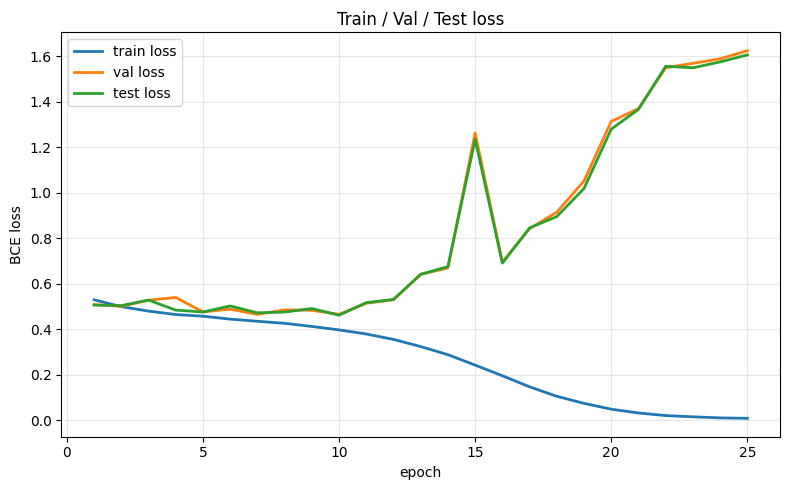

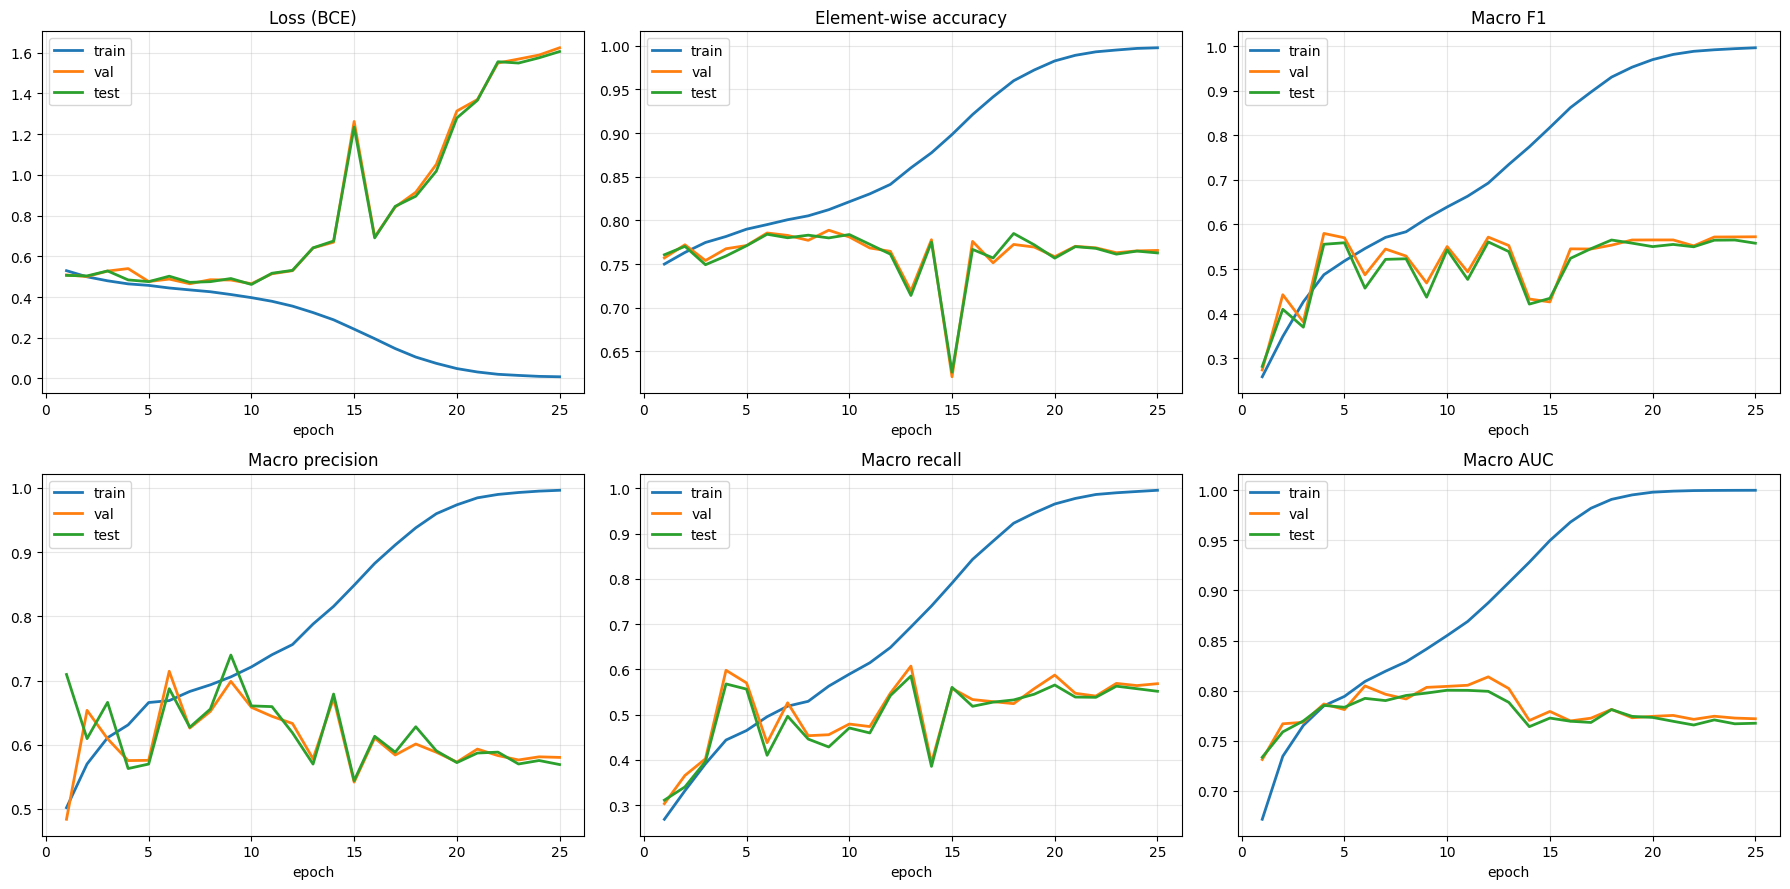

In [14]:
plot_loss_only(history)
plot_history(history)

## 6. Final evaluation (best-validation-loss checkpoint, threshold 0.5)

In [15]:
res = {}
for name, loader in [("val", val_loader), ("test", test_loader)]:
    res[name] = evaluate(model, loader, criterion, device)

rows = []
for name, (loss, y, p) in res.items():
    m = metrics(y, p); m["loss"] = loss; m["auc"] = macro_auc(y, p); rows.append(pd.Series(m, name=name))
print(pd.DataFrame(rows)[["loss", "acc", "precision", "recall", "f1", "auc"]].round(4))

_, ytest, ptest = res["test"]
print("\nPer-label test reports")
for i, l in enumerate(LABELS):
    print(f"\n{l}:")
    print(classification_report(ytest[:, i], (ptest[:, i] > 0.5).astype(int),
                                target_names=["Negative", "Positive"], digits=4, zero_division=0))

        loss     acc  precision  recall      f1     auc
val   0.4652  0.7827     0.6259  0.5262  0.5450  0.7963
test  0.4721  0.7801     0.6272  0.4965  0.5218  0.7900

Per-label test reports

Cardiomegaly:
              precision    recall  f1-score   support

    Negative     0.8393    0.8890    0.8634      1433
    Positive     0.5859    0.4797    0.5275       469

    accuracy                         0.7881      1902
   macro avg     0.7126    0.6844    0.6955      1902
weighted avg     0.7768    0.7881    0.7806      1902


Edema:
              precision    recall  f1-score   support

    Negative     0.7671    0.6167    0.6838       908
    Positive     0.7031    0.8290    0.7608       994

    accuracy                         0.7277      1902
   macro avg     0.7351    0.7229    0.7223      1902
weighted avg     0.7336    0.7277    0.7240      1902


Pneumothorax:
              precision    recall  f1-score   support

    Negative     0.8384    0.9716    0.9001      1548
    Pos

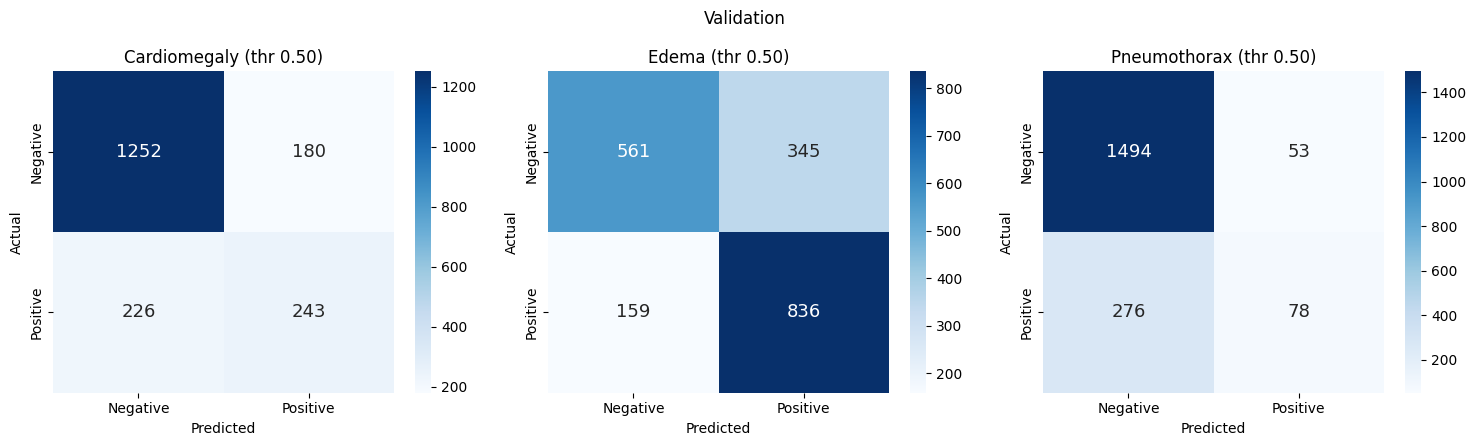

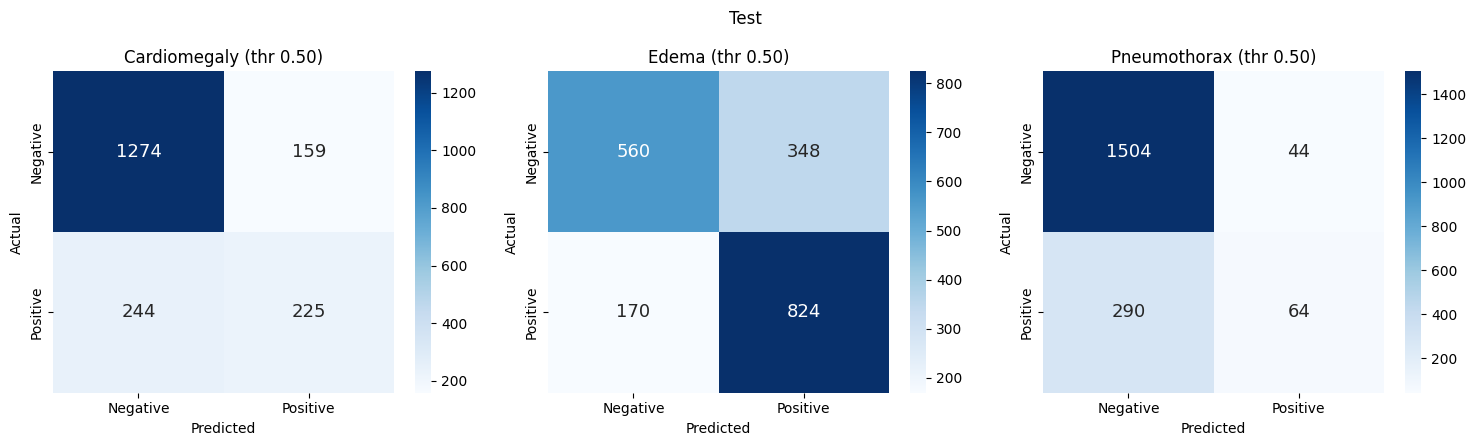

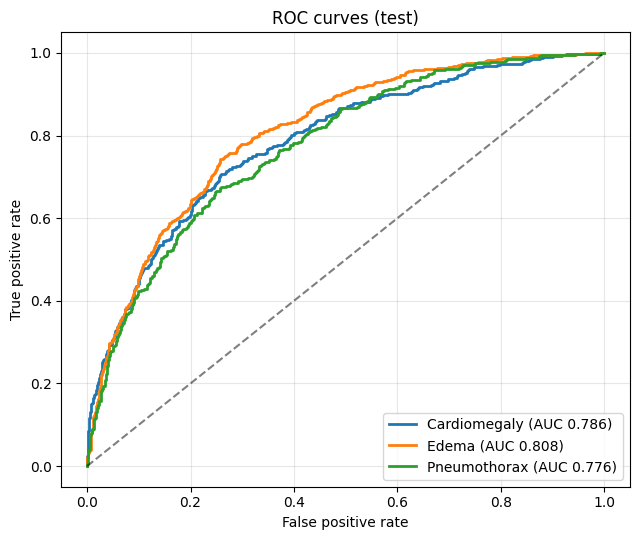

In [16]:
plot_confusions(res["val"][1],  res["val"][2],  LABELS, "Validation", "confusion_val.png")
plot_confusions(ytest, ptest, LABELS, "Test", "confusion_test.png")
plot_roc(ytest, ptest, LABELS)

## 7. (Optional) Per-label thresholds tuned on validation

With rare labels, a fixed 0.5 threshold often gives low recall. This picks, for each label, the threshold that maximises **validation** F1 and applies it unchanged to the test set (no tuning on test).

tuned thresholds: {'Cardiomegaly': np.float64(0.26), 'Edema': np.float64(0.42), 'Pneumothorax': np.float64(0.16)}
test metrics @0.5  : {'acc': 0.7801, 'precision': 0.6272, 'recall': 0.4965, 'f1': 0.5218}
test metrics @tuned: {'acc': 0.7233, 'precision': 0.5004, 'recall': 0.7533, 'f1': 0.6}


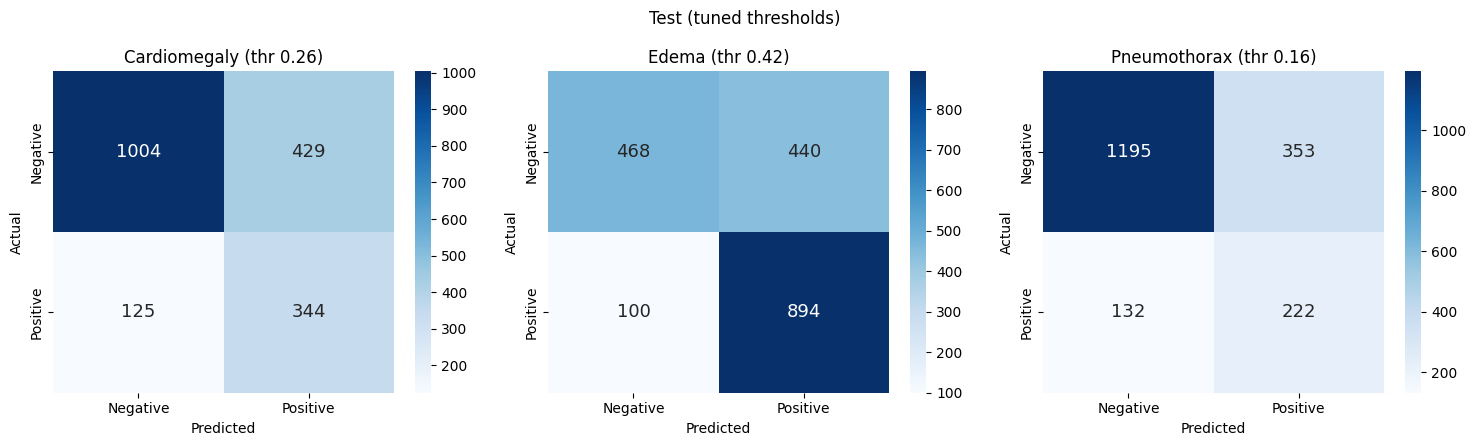

In [17]:
from sklearn.metrics import f1_score
_, yval, pval = res["val"]
grid = np.linspace(0.02, 0.98, 49)
best_thr = np.array([grid[np.argmax([f1_score(yval[:, i], (pval[:, i] > t).astype(int), zero_division=0) for t in grid])]
                     for i in range(NUM_CLASSES)])
print("tuned thresholds:", dict(zip(LABELS, best_thr.round(2))))
print("test metrics @0.5  :", {k: round(float(v), 4) for k, v in metrics(ytest, ptest, 0.5).items()})
print("test metrics @tuned:", {k: round(float(v), 4) for k, v in metrics(ytest, ptest, best_thr).items()})
plot_confusions(ytest, ptest, LABELS, "Test (tuned thresholds)", "confusion_test_tuned.png", thr=best_thr)

## Notes
- Elementwise accuracy is inflated when labels are rare; rely on per-label precision / recall / F1 / AUC.
- The reference notebook evaluates and checkpoints on the same validation split. Here the test split is untouched by model selection. Because this is a stratified subset, the splits differ from the reference's.
- Subset mode: change `SUBSET_FRACTION` (1.0 = all data) and `IMG_SIZE`. Caches are reused on re-runs, so only the first run pays the decoding cost.
- `USE_AUGMENTATION=True` applies flip + rotation (+/-10 deg) + brightness/contrast on the GPU, similar to the reference notebook.
- Best weights: `best_mobileformer_chexpert.pt`; figures are saved as PNGs in the working directory.